# Step 5: Does area deprivation explain satisfaction?

The model in notebook 3 explains almost 60% of the differences in overall satisfaction, but some landlords still sit well above or below what their operations predict. The first explanation that came to mind was deprivation: **are tenants in more deprived areas less satisfied?** Tenants in deprived areas often report lower satisfaction, for reasons a landlord can only partly control, so I wanted to test it properly.

**My plan:**
1. Find out where each housing association's homes are, by local authority, from the **Statistical Data Return (SDR)**
2. Give each landlord a **stock-weighted deprivation score**: the average deprivation of the local authorities its homes are in, weighted by how many homes it has in each
3. Add that score to the notebook 3 model and see whether the model gets better
4. Do the same for each of the seven **domains** of deprivation (income, employment, education, health, crime, barriers to housing and services, living environment)

**Data (all public):**
- RSH *Tenant Satisfaction Measures 2025: full data set* (the same file as notebooks 1 to 4)
- RSH *Private registered providers data release 2025, full data (zip, V1.1)* from the SDR
- MHCLG *English Indices of Deprivation 2025, File 10: Local Authority District summaries (lower tier, v2)*

## 1. Load the files

In Colab, I choose **all three files at once** when the upload button appears (holding Ctrl or Cmd to select several).

In [1]:
import pandas as pd
import numpy as np
# zipfile lets me read files straight out of the SDR zip without unzipping it first.
import zipfile
import re
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
import matplotlib.pyplot as plt
import os

# Upload in Colab, or use the data folder on my own computer.
try:
    from google.colab import files
    uploaded = files.upload()
    # There are three files this time, so I wrote a little function that finds an
    # uploaded file by a bit of its name.
    def pick(text):
        return next(name for name in uploaded if text in name)
    tsm_path = pick("TSM")          # the Tenant Satisfaction Measures file
    sdr_path = pick("PRP_Data")     # the SDR full data release zip
    iod_path = pick("File_10")      # the Indices of Deprivation local authority summaries
except ImportError:
    tsm_path = "../data/2025_TSM_Full_Data_v1.1_FINAL.xlsx"
    sdr_path = "../data/PRP_Data_Release_2025_Full_Data_FINAL_V1.1.zip"
    iod_path = "../data/File_10_-_IoD2025_Local_Authority_District_Summaries__lower-tier__v2.xlsx"

# Print the file names to check it picked the right ones.
print(tsm_path, sdr_path, iod_path, sep="\n")

../data/2025_TSM_Full_Data_v1.1_FINAL.xlsx
../data/PRP_Data_Release_2025_Full_Data_FINAL_V1.1.zip
../data/File_10_-_IoD2025_Local_Authority_District_Summaries__lower-tier__v2.xlsx


## 2. The satisfaction data and the notebook 3 model inputs

This is the same loading code as notebooks 2 to 4 (load the TSM sheets, shorten the names, join them, keep housing associations), plus the same survey method, size and region groupings as notebook 3.

In [2]:
# The loading code expects the file location in a variable called "path".
path = tsm_path

# This is the same loading and joining I worked out in notebooks 1 and 2, just copied in
# so this notebook runs on its own. re is Python's library for matching text patterns.
import re

# RSH puts codes like [X] in cells instead of leaving them blank, so I tell pandas to treat
# them as missing: [X] left blank, [Z] not required, [E] excluded, [U] couldn't be calculated.
missing_codes = ["[X]", "[Z]", "[E]", "[U]"]

# The two sheets have their headers on different rows (row 11 and row 10 in Excel).
lcra = pd.read_excel(path, sheet_name="TSM25_LCRA_Perception", header=10, na_values=missing_codes)
mi = pd.read_excel(path, sheet_name="TSM25_Management_Info", header=9, na_values=missing_codes)

# The survey column names are whole sentences ending in a code like (TP01), so I use a pattern
# to find them and keep just the code as the new name.
tp_pattern = r"^Proportion of respondents who report that they are satisfied.*\((TP\d{2})\)\d*$"
rename_map = {}
for col in lcra.columns:
    match = re.match(tp_pattern, col)
    if match:
        rename_map[col] = match.group(1)

# Shorter names for the other columns I use a lot.
rename_map.update({
    "Landlord name": "landlord",                                          # the landlord's name
    "Landlord code": "code",                                              # RSH's unique ID for each landlord
    "Landlord type": "type",                                              # PRP = housing association, LA = council
    "Landlord group size (homes owned, LCRA and LCHO combined)": "size_band",  # size band
    "Landlord predominant region": "region",                              # region
    "Predominant collection method": "method",                            # main survey method
})

# Pick out the 12 TP codes, then rename and keep only the columns I need.
tp_cols = sorted(name for name in rename_map.values() if name.startswith("TP"))
perception = lcra.rename(columns=rename_map)[
    ["landlord", "code", "type", "size_band", "region", "method"] + tp_cols]


# My function for finding exactly one column whose name contains all the bits of text I give it.
# The assert stops everything if it finds none or several, so I can't grab the wrong column by accident.
def find_col(df, must_contain, starts_with=None):
    """Return the one column whose name contains every text in must_contain."""
    hits = []
    for c in df.columns:
        contains_all = all(text in c for text in must_contain)
        starts_ok = starts_with is None or c.startswith(starts_with)
        if contains_all and starts_ok:
            hits.append(c)
    assert len(hits) == 1, f"Expected 1 match for {must_contain}, found {len(hits)}: {hits}"
    return hits[0]

# The operational measures I want: {my short name: (text in the column name, what it starts with)}.
mi_measures = {
    "gas_safety_pc":            (["(BS01)"], "Proportion"),            # homes with gas safety checks done
    "asb_per_1000":             (["(NM01 1)"], "Number of anti-social"),  # ASB cases per 1,000 homes
    "non_decent_pc":            (["(RP01)"], "Proportion"),            # homes not meeting Decent Homes
    "repairs_on_time_pc":       (["(RP02 1)"], "Proportion"),          # non-emergency repairs on time
    "emergency_on_time_pc":     (["(RP02 2)"], "Proportion"),          # emergency repairs on time
    "repair_target_days":       (["target timescale for non-emergency repairs used to calculate"], "What is your"),
    "complaints_s1_per_1000":   (["(CH01 1)"], "LCRA"),                # stage 1 complaints per 1,000 homes
    "complaints_s1_on_time_pc": (["(CH02 1)"], "LCRA"),                # stage 1 complaints answered on time
    "complaints_s2_per_1000":   (["(CH01 2)"], "LCRA"),                # stage 2 complaints per 1,000 homes
    "complaints_s2_on_time_pc": (["(CH02 2)"], "LCRA"),                # stage 2 complaints answered on time
}
mi_cols = list(mi_measures)

# Build a table of landlord code plus one column per measure, as numbers
# (errors="coerce" turns anything that isn't a number into a blank).
management = pd.DataFrame({"code": mi["Landlord code"]})
for short, (texts, start) in mi_measures.items():
    col = find_col(mi, texts, start)
    management[short] = pd.to_numeric(mi[col], errors="coerce")

# Join the two tables on landlord code (like a VLOOKUP). validate="one_to_one" is a safety check
# that no code appears twice. Then keep housing associations only ("PRP").
df = perception.merge(management, on="code", how="inner", validate="one_to_one")
has = df[df["type"] == "PRP"].copy()
print("Joined landlords:", len(df), " Housing associations:", len(has))

# Same groupings as notebook 3: the rarer survey methods go into "Other", because groups with
# only a handful of landlords give unreliable results.
has["method_group"] = has["method"].where(
    has["method"].isin(["Telephone", "Internet", "Postal"]), "Other")

# Setting a category order means the first one in each list is the "reference group" the model
# compares everything else against. I picked the most common group each time.
has["method_group"] = pd.Categorical(has["method_group"], ["Telephone", "Internet", "Postal", "Other"])
has["size_band"] = pd.Categorical(has["size_band"], ["5,000-40,000", "<5,000", ">40,000"])
has["region"] = pd.Categorical(has["region"], ["South", "North", "Midlands", "London", "Mixed"])

# Landlord codes are a mix of plain numbers and text like L4240, and pandas reads some of them as
# numbers. I make them all text, otherwise they won't match the SDR codes later.
has["code"] = has["code"].astype(str)

Joined landlords: 352  Housing associations: 195


## 3. Where each landlord's homes are (SDR stock by local authority)

The SDR zip has loads of CSV files in it. The one I need is **File 04, Stock by LA**, which has one row per landlord per local authority, with the number of homes of each type. Like a lot of official files, it has some rows of notes above the real headers, so I find the header row by looking for the text "PRP name".

I count **low cost rental homes owned**: general needs (self-contained and bedspaces), supported housing and housing for older people, because those are the homes whose tenants answer the TSM survey.

In [3]:
# A function to read one CSV out of the zip and skip the notes above the headers.
def read_sdr(zip_path, file_label):
    """Read the SDR CSV whose name contains file_label, e.g. 'File 04'."""
    # "with" closes the zip again automatically when I'm done with it.
    with zipfile.ZipFile(zip_path) as z:
        name = next(n for n in z.namelist() if file_label in n)
        # First I read it with no headers, just to find which row says "PRP name".
        # encoding="latin-1" copes with some special characters in RSH's files.
        with z.open(name) as f:
            raw = pd.read_csv(f, encoding="latin-1", header=None)
        header_row = raw.index[raw.iloc[:, 0].astype(str).str.strip() == "PRP name"][0]
        # Then I read it again properly, telling pandas where the headers are.
        with z.open(name) as f:
            return pd.read_csv(f, encoding="latin-1", header=header_row)


stock = read_sdr(sdr_path, "File 04")
print("Stock rows:", stock.shape)

# The four kinds of owned rental homes I want to count, found by how their column names start.
home_types = [
    "General needs - Self-contained - Owned",   # ordinary flats and houses
    "General needs - Bedspace - Owned",         # shared housing, counted per bedspace
    "Supported housing - Owned",                # supported housing
    "Housing for older people - Owned",         # older people's housing
]
home_cols = [next(col for col in stock.columns if col.startswith(t)) for t in home_types]

# Make them numbers ("[x]" for not available becomes blank).
for col in home_cols:
    stock[col] = pd.to_numeric(stock[col], errors="coerce")

# Add the four together. min_count=1 means if all four are blank the total is blank, not 0.
stock["lcra_homes"] = stock[home_cols].sum(axis=1, min_count=1)
# Short names for the landlord code (as text, to match the TSM codes) and the local authority code.
stock["code"] = stock["PRP registration number"].astype(str)
stock["la_code"] = stock["LA code"]

# A quick check: how many homes and local authority areas the file covers, and a peek at the first rows.
print(f"Homes counted: {stock['lcra_homes'].sum():,.0f} across {stock['la_code'].nunique()} local authority areas")
stock.dropna(subset=["lcra_homes"])[["PRP name", "Local Authority name", "la_code", "lcra_homes"]].head()

Stock rows: (10263, 32)
Homes counted: 2,699,908 across 301 local authority areas


,PRP name,Local Authority name,la_code,lcra_homes
1,20-20 Housing Co-operative Limited,Birmingham,E08000025,49.0
2,3CHA Ltd,Milton Keynes,E06000042,7.0
3,54 North Homes Limited,East Riding of Yorkshire,E06000011,89.0
4,54 North Homes Limited,Kirklees,E08000034,8.0
5,54 North Homes Limited,Leeds,E08000035,1436.0


## 4. Allow for group structures

This bit took some thinking. Some landlords submit their TSMs for a whole **group**, but in the SDR their homes are split across several registered companies. **File 02, Group Information** lists each company's registered parent.

So for each TSM landlord I count its own homes **plus** the homes of every registered subsidiary below it (and subsidiaries of subsidiaries), **unless** that subsidiary reports its own TSMs, otherwise I'd be counting the same homes twice.

In [4]:
groups = read_sdr(sdr_path, "File 02")

# Keep the rows that have a registered parent, and just the child and parent codes.
links = groups[groups["Registered Parent's code"].notna()][
    ["PRP registration number", "Registered Parent's code"]].drop_duplicates()

# Build a lookup of {parent code: [its children's codes]}.
# setdefault creates an empty list for a parent the first time I see it.
children = {}
for child, parent in zip(links["PRP registration number"], links["Registered Parent's code"]):
    children.setdefault(str(parent), []).append(str(child))

# The codes of every landlord that reports TSMs itself.
tsm_codes = set(has["code"])


# My function to get a landlord plus all the subsidiaries I should count with it.
# It works like a to-do list: check a company's children, add them, then check their children too.
def group_members(code):
    """The landlord itself plus every registered subsidiary below it, except any that report to TSM separately."""
    found = [code]
    to_check = [code]
    while to_check:
        current = to_check.pop()
        for child in children.get(current, []):
            # Skip anything already counted, or that reports TSMs in its own right.
            if child not in found and child not in tsm_codes:
                found.append(child)
                to_check.append(child)
    return found


# As a check: how many companies does each landlord end up covering?
member_counts = has["code"].apply(lambda code: len(group_members(code)))
member_counts.value_counts().sort_index()

code
1    152
2     22
3     11
4      7
6      2
7      1
Name: count, dtype: int64

Most landlords (152) are just one company, but some cover up to 7. (`lambda code: ...` is a tiny one-line function without a name, and `.apply()` runs it on every value in the column.)

## 5. Deprivation scores by local authority

The Indices of Deprivation file has one sheet per domain. On each sheet, the **average score** column gives each local authority's average deprivation (higher means more deprived). I collect the overall Index of Multiple Deprivation (IMD) and all seven domains into one table.

In [5]:
# {sheet name: how that sheet's score column starts}. The sheet names are shorter than the domain names.
domains = {
    "IMD": "IMD",
    "Income": "Income",
    "Employment": "Employment",
    "Education": "Education, Skills and Training",
    "Health": "Health Deprivation and Disability",
    "Crime": "Crime",
    "Barriers": "Barriers to Housing and Services",
    "Living": "Living Environment",
}

# Read each sheet and grab its average score column, labelled by local authority code.
scores = {}
for sheet, prefix in domains.items():
    sheet_data = pd.read_excel(iod_path, sheet_name=sheet)
    # Some column names had a space on the end, which stopped my lookups working, so I strip them.
    sheet_data.columns = [col.strip() for col in sheet_data.columns]
    scores[sheet] = sheet_data.set_index("Local Authority District code (2024)")[f"{prefix} - Average score"]

# Put them together: one row per local authority, one column per domain.
la_deprivation = pd.DataFrame(scores)
print(la_deprivation.shape)
la_deprivation.head()

(296, 8)


,IMD,Income,Employment,Education,Health,Crime,Barriers,Living
Local Authority District code (2024),,,,,,,,
E06000001,37.580,0.357,0.247,30.453,1.199,0.638,15.270,17.012
E06000002,40.037,0.375,0.233,38.536,1.023,0.952,20.273,21.818
E06000003,30.336,0.297,0.209,25.343,0.745,0.437,16.587,18.178
E06000004,25.830,0.256,0.172,22.910,0.723,0.208,15.154,13.087
E06000005,25.713,0.248,0.166,24.246,0.575,0.283,14.779,21.474


In [6]:
# Before joining, I checked the local authority codes match between the two files.
# ~ means "not", so ~matched is the rows that DON'T match.
matched = stock["la_code"].isin(la_deprivation.index)
unmatched_homes = stock.loc[~matched, "lcra_homes"].sum()
total_homes = stock["lcra_homes"].sum()
print("Unmatched areas:", sorted(stock.loc[~matched & stock["lcra_homes"].gt(0), "Local Authority name"].unique()))
print(f"Homes in unmatched areas: {unmatched_homes:,.0f} of {total_homes:,.0f}")

# Keep only rows with a matching local authority and at least one home.
stock_matched = stock[matched & (stock["lcra_homes"] > 0)]

Unmatched areas: ['Northern Ireland', 'Scotland', 'Wales']
Homes in unmatched areas: 1,437 of 2,699,908


The only rows that don't match are homes outside England (Wales, Scotland, Northern Ireland), which the English indices don't cover. That's about 1,400 homes out of 2.7 million, so it's fine to drop them.

## 6. A stock-weighted deprivation score for each landlord

For each landlord, I take its homes in each local authority and turn them into **shares** (for example 70% in one local authority and 30% in another). Then I average the local authorities' deprivation scores using those shares as weights. It's a **weighted average**, the same idea as SUMPRODUCT in Excel.

In [7]:
rows = []
for code in has["code"]:
    # This landlord's stock rows, including the rest of its group.
    own_rows = stock_matched[stock_matched["code"].isin(group_members(code))]
    # Homes per local authority (a group can have several companies in the same area, so I add them up).
    homes = own_rows.groupby("la_code")["lcra_homes"].sum()
    # Each local authority's share of the landlord's homes. These add up to 1.
    shares = homes / homes.sum()
    # The weighted average: multiply each area's scores by its share, then add them up.
    area_scores = la_deprivation.loc[homes.index]
    weighted = area_scores.mul(shares, axis=0).sum()
    # One row per landlord: code, total homes, how many local authorities, and a score per domain.
    row = {"code": code, "sdr_homes": homes.sum(), "n_las": len(homes)}
    for domain, value in weighted.items():
        row["dep_" + domain] = value
    rows.append(row)

landlord_deprivation = pd.DataFrame(rows)
# I saved this as a CSV so I (or anyone else) can reuse it without rerunning all of this.
landlord_deprivation.to_csv("landlord_deprivation.csv", index=False)
landlord_deprivation.head()

,code,sdr_homes,n_las,dep_IMD,dep_Income,dep_Employment,dep_Education,dep_Health,dep_Crime,dep_Barriers,dep_Living
0,L4240,21417.0,66,17.600534,0.209838,0.103401,16.103519,-0.537718,-0.029848,25.852486,23.280339
1,L4172,35359.0,37,14.468612,0.158380,0.094619,16.848212,-0.637459,-0.293661,23.820882,15.509933
2,L4229,6143.0,17,22.756206,0.219714,0.145550,22.699169,0.110697,-0.207708,26.767313,19.274001
3,LH4095,35759.0,242,24.062423,0.250237,0.146303,23.730617,0.150248,0.123624,21.152315,22.798768
4,L3713,1105.0,3,36.909444,0.356815,0.181843,26.720125,0.988760,0.826870,29.099595,27.796531


### Sense check: do the SDR home counts match the TSM tenant numbers?

If my group handling worked, each landlord's SDR homes should be close to the number of tenants in its TSM survey population. A ratio of about 1 would mean it's working.

In [8]:
# Join the deprivation scores onto the satisfaction data.
has = has.merge(landlord_deprivation, on="code", how="left", validate="one_to_one")

# Find the TSM tenant population column, and look it up by landlord code.
tenant_col = [col for col in lcra.columns if col.startswith("Relevant") and "(LCRA)" in col][0]
tenants = lcra.set_index(lcra["Landlord code"].astype(str))[tenant_col]
has["homes_to_tenants"] = has["sdr_homes"] / has["code"].map(tenants)

# I'm hoping for a median close to 1.
print(has["homes_to_tenants"].describe().round(2))

count    195.00
mean       1.02
std        0.04
min        0.88
25%        1.00
50%        1.00
75%        1.02
max        1.35
Name: homes_to_tenants, dtype: float64


It worked: the median ratio is 1.00, and 189 of the 195 landlords (97%) are between 0.9 and 1.1. That's about as close as I could hope for.

## 7. Is deprivation linked to satisfaction?

A simple check first: the Spearman correlation between each deprivation score and overall satisfaction (TP01), across the 195 housing associations.

In [9]:
# All the columns I created start with "dep_".
dep_cols = [col for col in has.columns if col.startswith("dep_")]

# The Spearman correlation of each one with TP01.
simple = pd.Series({col: spearmanr(has[col], has["TP01"]).statistic for col in dep_cols},
                   name="Spearman with TP01")
simple.round(2).sort_values()

dep_Barriers     -0.22
dep_Living       -0.22
dep_Income       -0.08
dep_Crime        -0.05
dep_IMD           0.02
dep_Employment    0.09
dep_Health        0.16
dep_Education     0.21
Name: Spearman with TP01, dtype: float64

The overall IMD has almost no link with satisfaction (+0.02). The strongest links are still weak, around 0.2: **barriers to housing and services** and **living environment** (both −0.22), and **education** (+0.21), which goes the "wrong" way (more deprived, slightly more satisfied). I think that's region again: northern housing associations tend to be in more deprived areas *and* have higher satisfaction, which section 8 shows.

## 8. Add deprivation to the model

Now the proper test. I take the **notebook 3 model** (the four operational measures plus survey method, size and region) and add one deprivation score at a time. For each one I record:

- the **effect** of going from a less deprived landlord (25th percentile) to a more deprived one (75th), with its 95% confidence interval and p-value
- **R-squared** and **cross-validated R-squared** (does it predict unseen landlords any better?)

In [10]:
# The same inputs as notebook 3.
operations = ["complaints_s2_per_1000", "non_decent_pc", "repairs_on_time_pc", "complaints_s1_on_time_pc"]
context = "C(method_group) + C(size_band) + C(region)"
# Drop anyone missing an input, so every model uses exactly the same landlords.
model_data = has.dropna(subset=["TP01"] + operations + dep_cols).copy()
# The same fixed 5-way split as notebook 3, so the results repeat.
folds = KFold(n_splits=5, shuffle=True, random_state=42)


# I'm fitting nine models here, so I wrote one function to fit a model and pull out
# everything I want to compare, rather than copying the same code nine times.
def fit_and_score(extra=None):
    """Fit the notebook 3 model, optionally with one extra input, and summarise it."""
    inputs = operations + ([extra] if extra else [])
    formula = f"TP01 ~ {' + '.join(inputs)} + {context}"
    result = smf.ols(formula, data=model_data).fit(cov_type="HC3")
    # Cross-validated R-squared, using the same inputs statsmodels built.
    X = pd.DataFrame(result.model.exog, columns=result.model.exog_names).drop(columns="Intercept")
    cv = cross_val_score(LinearRegression(), X, result.model.endog, cv=folds, scoring="r2").mean()
    summary = {"R-squared": result.rsquared, "CV R-squared": cv}
    # If I added a deprivation score, also work out its effect over a typical gap (25th to 75th percentile).
    if extra:
        iqr = model_data[extra].quantile(0.75) - model_data[extra].quantile(0.25)
        ci = result.conf_int().loc[extra]
        summary["effect (25th to 75th)"] = result.params[extra] * iqr
        summary["CI low"] = ci[0] * iqr
        summary["CI high"] = ci[1] * iqr
        summary["p-value"] = result.pvalues[extra]
    return summary, result


# First the model without deprivation, then one with each score added.
baseline_summary, baseline = fit_and_score()
results = {"No deprivation (notebook 3)": baseline_summary}
for col in dep_cols:
    # col[4:] chops off "dep_", so the rows are labelled "IMD", "Income" and so on.
    results["+ " + col[4:]], _ = fit_and_score(col)

comparison = pd.DataFrame(results).T
comparison.round(3)

,R-squared,CV R-squared,effect (25th to 75th),CI low,CI high,p-value
No deprivation (notebook 3),0.589,0.422,NaN,NaN,NaN,NaN
+ IMD,0.593,0.408,-1.241,-3.007,0.526,0.169
+ Income,0.591,0.404,-0.788,-2.550,0.974,0.381
+ Employment,0.591,0.413,-0.961,-2.671,0.749,0.271
+ Education,0.596,0.414,-1.489,-3.150,0.173,0.079
+ Health,0.590,0.415,-0.798,-2.630,1.035,0.394
+ Crime,0.592,0.414,-1.053,-2.735,0.629,0.220
+ Barriers,0.595,0.423,-1.288,-2.709,0.133,0.076
+ Living,0.590,0.420,-0.614,-2.248,1.021,0.462


**What the table tells me:**

- **None of the domains clearly improves the model.** R-squared barely moves (from 0.589 to 0.596 at most), and cross-validated R-squared stays at about 0.40 to 0.42, so it's no better at predicting landlords it hasn't seen.
- **None of the confidence intervals is clearly away from zero.** The lowest p-values are Barriers (0.08) and Education (0.08). I tested eight scores, so one or two borderline results are what I'd expect by chance anyway.

### Why region matters here

Region and deprivation overlap: housing associations in the North are, on average, in more deprived areas than those in the South. I wondered what would happen without region in the model, and overall deprivation does become statistically significant. So some of what looked like a "region effect" in notebook 3 might really be deprivation, or the other way round. Either way, it's a reminder that region and deprivation are hard to separate in this data.

In [11]:
# The same model with IMD, but without region.
no_region = smf.ols(f"TP01 ~ {' + '.join(operations)} + dep_IMD + C(method_group) + C(size_band)",
                    data=model_data).fit(cov_type="HC3")
print(f"IMD coefficient without region: {no_region.params['dep_IMD']:.3f} "
      f"(95% CI {no_region.conf_int().loc['dep_IMD', 0]:.3f} to {no_region.conf_int().loc['dep_IMD', 1]:.3f}, "
      f"p = {no_region.pvalues['dep_IMD']:.3f})")
# The median deprivation score in each region, to see the overlap (observed=True skips empty groups).
model_data.groupby("region", observed=True)["dep_IMD"].median().round(1)

IMD coefficient without region: -0.158 (95% CI -0.297 to -0.018, p = 0.027)


region
South       17.1
North       28.3
Midlands    25.0
London      25.0
Mixed       23.6
Name: dep_IMD, dtype: float64

## 9. Charts

Same style as notebook 4.

In [12]:
# My house style from notebook 4 (colours, fonts, gridlines). Notebook 4 explains each setting.
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, HIGHLIGHT, CONTEXT = "#e1e0d9", "#c3c2b7", "#2a78d6", "#c3c2b7"
SOURCE = ("Sources: RSH Tenant Satisfaction Measures 2024/25; RSH Statistical Data Return 2025; "
          "MHCLG English Indices of Deprivation 2025")
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_2, "axes.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
})


# Title, subtitle and source in the same places as notebook 4.
def titles(fig, title, subtitle):
    fig.text(0.02, 0.98, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.02, 0.925, subtitle, ha="left", va="top", fontsize=10, color=INK_2)
    fig.text(0.02, 0.015, SOURCE, ha="left", va="bottom", fontsize=8, color=MUTED)


os.makedirs("charts", exist_ok=True)

### Chart 5: Deprivation against satisfaction

A scatter plot like chart 2: each housing association as a dot, with a trend line.

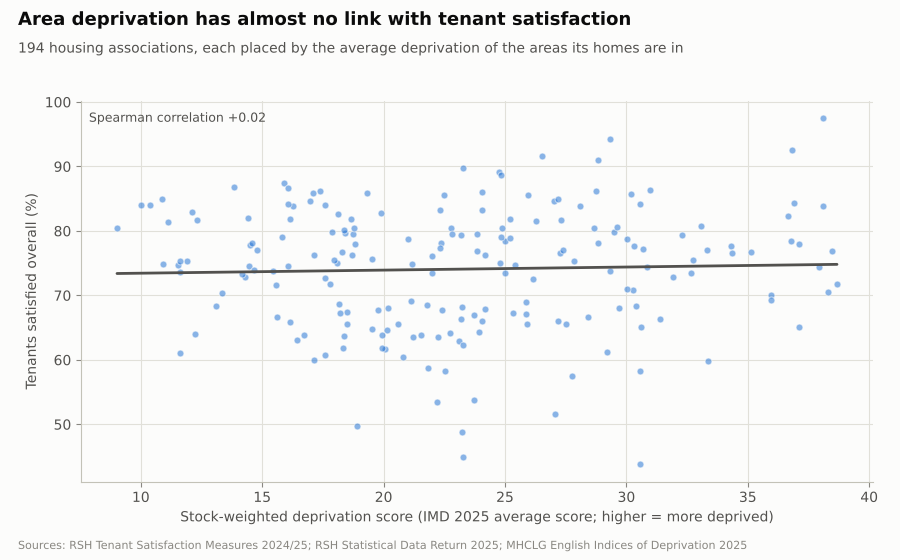

In [13]:
fig, ax = plt.subplots(figsize=(9, 5.6))
fig.subplots_adjust(left=0.09, right=0.97, top=0.82, bottom=0.14)

# Every housing association as a dot, with a straight trend line through them.
ax.scatter(model_data["dep_IMD"], model_data["TP01"], s=24, color=HIGHLIGHT, alpha=0.55,
           edgecolors=SURFACE, linewidths=0.8)
slope, intercept = np.polyfit(model_data["dep_IMD"], model_data["TP01"], 1)
xs = np.linspace(model_data["dep_IMD"].min(), model_data["dep_IMD"].max(), 50)
ax.plot(xs, intercept + slope * xs, color=INK_2, linewidth=2, solid_capstyle="round")

ax.set_xlabel("Stock-weighted deprivation score (IMD 2025 average score; higher = more deprived)")
ax.set_ylabel("Tenants satisfied overall (%)")
# The correlation in the empty top-left corner. transform=ax.transAxes means positions from 0 to 1
# across the chart, rather than data values.
rho = spearmanr(model_data["dep_IMD"], model_data["TP01"]).statistic
ax.text(0.01, 0.97, f"Spearman correlation {rho:+.2f}", transform=ax.transAxes,
        ha="left", va="top", fontsize=9, color=INK_2)

titles(fig, "Area deprivation has almost no link with tenant satisfaction",
       f"{len(model_data)} housing associations, each placed by the average deprivation of the areas its homes are in")
fig.savefig("charts/5_deprivation_scatter.png", dpi=200)
plt.show()

### Chart 6: The effect of each deprivation score in the model

The "effect" column from section 8: what going from a less deprived landlord (25th percentile) to a more deprived one (75th) is worth in satisfaction, with everything in the notebook 3 model held the same. If a whisker crosses zero, I can't be sure the effect is real.

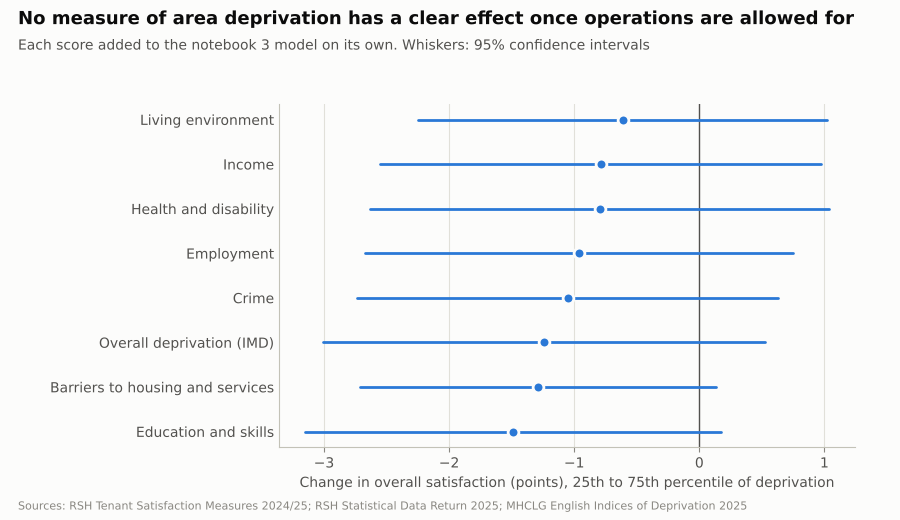

In [14]:
# Plain English names for the eight scores.
names = {"IMD": "Overall deprivation (IMD)", "Income": "Income", "Employment": "Employment",
         "Education": "Education and skills", "Health": "Health and disability", "Crime": "Crime",
         "Barriers": "Barriers to housing and services", "Living": "Living environment"}
# Every row except the baseline model, sorted by effect.
effects = comparison.drop(index="No deprivation (notebook 3)").sort_values("effect (25th to 75th)")
labels_ = [names[i.replace("+ ", "")] for i in effects.index]
y = np.arange(len(effects))

fig, ax = plt.subplots(figsize=(9, 5.2))
fig.subplots_adjust(left=0.31, right=0.95, top=0.80, bottom=0.14)

# A line at zero, then the whiskers (95% confidence intervals) and the dots.
ax.axvline(0, color=INK_2, linewidth=1)
ax.hlines(y, effects["CI low"], effects["CI high"], color=HIGHLIGHT, linewidth=2, capstyle="round")
ax.scatter(effects["effect (25th to 75th)"], y, s=60, color=HIGHLIGHT, edgecolors=SURFACE, linewidths=2, zorder=3)

ax.set_yticks(y, labels_)
ax.set_xlabel("Change in overall satisfaction (points), 25th to 75th percentile of deprivation")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)

titles(fig, "No measure of area deprivation has a clear effect once operations are allowed for",
       "Each score added to the notebook 3 model on its own. Whiskers: 95% confidence intervals")
fig.savefig("charts/6_deprivation_effects.png", dpi=200)
plt.show()

## What I found

- **Area deprivation is barely linked to tenant satisfaction** among housing associations (Spearman +0.02 for the overall IMD).
- **Adding deprivation to the model doesn't improve it.** All eight scores point the same way (slightly lower satisfaction in more deprived areas), but none has an effect clearly different from zero, and predictions for unseen landlords don't get any better (cross-validated R² 0.40 to 0.42, against 0.42 without).
- **Region and deprivation overlap.** Northern housing associations are in more deprived areas on average, and deprivation only becomes significant when region is left out.
- So deprivation doesn't explain why some landlords sit well below their predictions. That points to parts of tenants' experience the TSM operational measures don't capture, such as communication and whether tenants feel listened to.

**Limitations:**
- **Local authority averages are quite rough.** Social housing is often in the more deprived neighbourhoods within each local authority, so these scores probably understate how deprived tenants' own areas are. A neighbourhood-level (LSOA) version would need stock data by neighbourhood, which the public SDR doesn't have.
- **Area deprivation isn't tenant deprivation.** It describes places, not the actual households a landlord houses.
- **I tested eight scores**, so a borderline result or two is expected by chance.
- The same limits as notebook 3 still apply: one year of data, and correlation isn't causation.

**Next:** notebook 6 checks the other explanations I could think of: sampling error, how the survey was run, and the type of homes.